# Steel Surface Defect Detector
**NEU-DET data -> YOLO format -> train (MLflow) -> evaluate (mAP) -> ONNX export -> predictions figure -> drift reference**.

In [1]:
!nvidia-smi -L
import torch
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())

GPU 0: Tesla T4 (UUID: GPU-5b542df5-6de6-e6a5-ea73-d86ace4c1aa7)
torch 2.11.0+cu130 | cuda: True


## Get code

In [2]:
REPO_URL = "https://github.com/devinasawitrii/defect-detection-mlops.git"
import os
if not os.path.exists("defect-detection-mlops"):
    !git clone {REPO_URL}
%cd defect-detection-mlops

Cloning into 'defect-detection-mlops'...
remote: Enumerating objects: 107, done.
remote: Counting objects: 100% (107/107), done.
remote: Compressing objects: 100% (97/97), done.
remote: Total 107 (delta 42), reused 63 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (107/107), 59.81 KiB | 1.30 MiB/s, done.
Resolving deltas: 100% (42/42), done.
/content/defect-detection-mlops


In [3]:
!pip install -q "ultralytics>=8.4" mlflow onnx onnxruntime scikit-learn scipy pyyaml pandas kaggle

## NEU-DET Data (steel defects with bounding boxes)

In [4]:
from google.colab import files
uploaded = files.upload()   # choose kaggle.json
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d kaustubhdikshit/neu-surface-defect-database -p data/raw --unzip

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/kaustubhdikshit/neu-surface-defect-database
License(s): unknown
100% 26.4M/26.4M [00:00<00:00, 160MB/s]



In [5]:
!echo "xml files:" && find data/raw -name "*.xml" | wc -l
!echo "image files:" && find data/raw -type f \( -name "*.jpg" -o -name "*.bmp" -o -name "*.png" \) | wc -l
!find data/raw -name "*.xml" | head -3

xml files:
1800
image files:
1800
data/raw/NEU-DET/validation/annotations/pitted_surface_286.xml
data/raw/NEU-DET/validation/annotations/rolled-in_scale_279.xml
data/raw/NEU-DET/validation/annotations/scratches_276.xml


## Convert VOC to YOLO and split (de-duplication, stratified train/val/test)

In [6]:
!python -m src.prepare_data

{
  "xml_without_image": 0,
  "xml_without_valid_boxes": 0,
  "duplicates_dropped": 1,
  "train": {
    "images": 1259,
    "boxes": 2919
  },
  "val": {
    "images": 270,
    "boxes": 660
  },
  "test": {
    "images": 270,
    "boxes": 607
  }
}


In [7]:
import glob
import random
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
from src.prepare_data import CLASSES
from src.visualize import read_gt
from serving.inference import draw_detections
files = random.sample(
    glob.glob("data/processed/images/train/*"),
    min(6, len(glob.glob("data/processed/images/train/*"))))
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, f in zip(axes.ravel(), files):
    img = Image.open(f).convert("RGB")
    label_path = Path(
        f.replace("images", "labels").rsplit(".", 1)[0] + ".txt")
    gt = read_gt(label_path, CLASSES, img.size)
    ax.imshow(draw_detections(img, gt, CLASSES))
    ax.axis("off")
plt.suptitle("Training Samples with Ground-Truth Boxes")
plt.tight_layout()
plt.show()

## Train COCO-pretrained yolo26n.pt (transfer learning) and fine-tunes on NEU-DET.

In [8]:
!python -m src.train

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
2026/10/29 05:59:41 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/29 05:59:41 INFO mlflow.store.db.utils: Updating database tables
2026/10/29 05:59:44 INFO mlflow.tracking.fluent: Experiment with name 'neu-det-yolo' does not exist. Creating a new experiment.
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data

In [9]:
import mlflow
mlflow.set_tracking_uri("sqlite:///mlflow.db")
runs = mlflow.search_runs(experiment_names=["neu-det-yolo"])
runs[["tags.mlflow.runName", "params.train.model", "metrics.final/mAP50B", "metrics.final/mAP50-95B"]]

,tags.mlflow.runName,params.train.model,metrics.final/mAP50B,metrics.final/mAP50-95B
0,yolo26n-d6bd49f,yolo26n.pt,0.743164,0.427163


## Evaluate held-out test set (mAP)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 756.9±402.0 MB/s, size: 16.1 KB)
val: Scanning /content/defect-detection-mlops/data/processed/labels/test... 270 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 270/270 2.2Kit/s 0.1s
val: New cache created: /content/defect-detection-mlops/data/processed/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 4.4it/s 3.9s
                   all        270        607      0.733      0.729      0.779      0.475
Speed: 2.2ms preprocess, 5.2ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /content/defect-detection-mlops/runs/eval
test mAP@50=0.7789  mAP@50-95=0.4747
class              AP50    AP50-95
crazing            0.517   0.231
inclusion          0.803   0.469
patches     

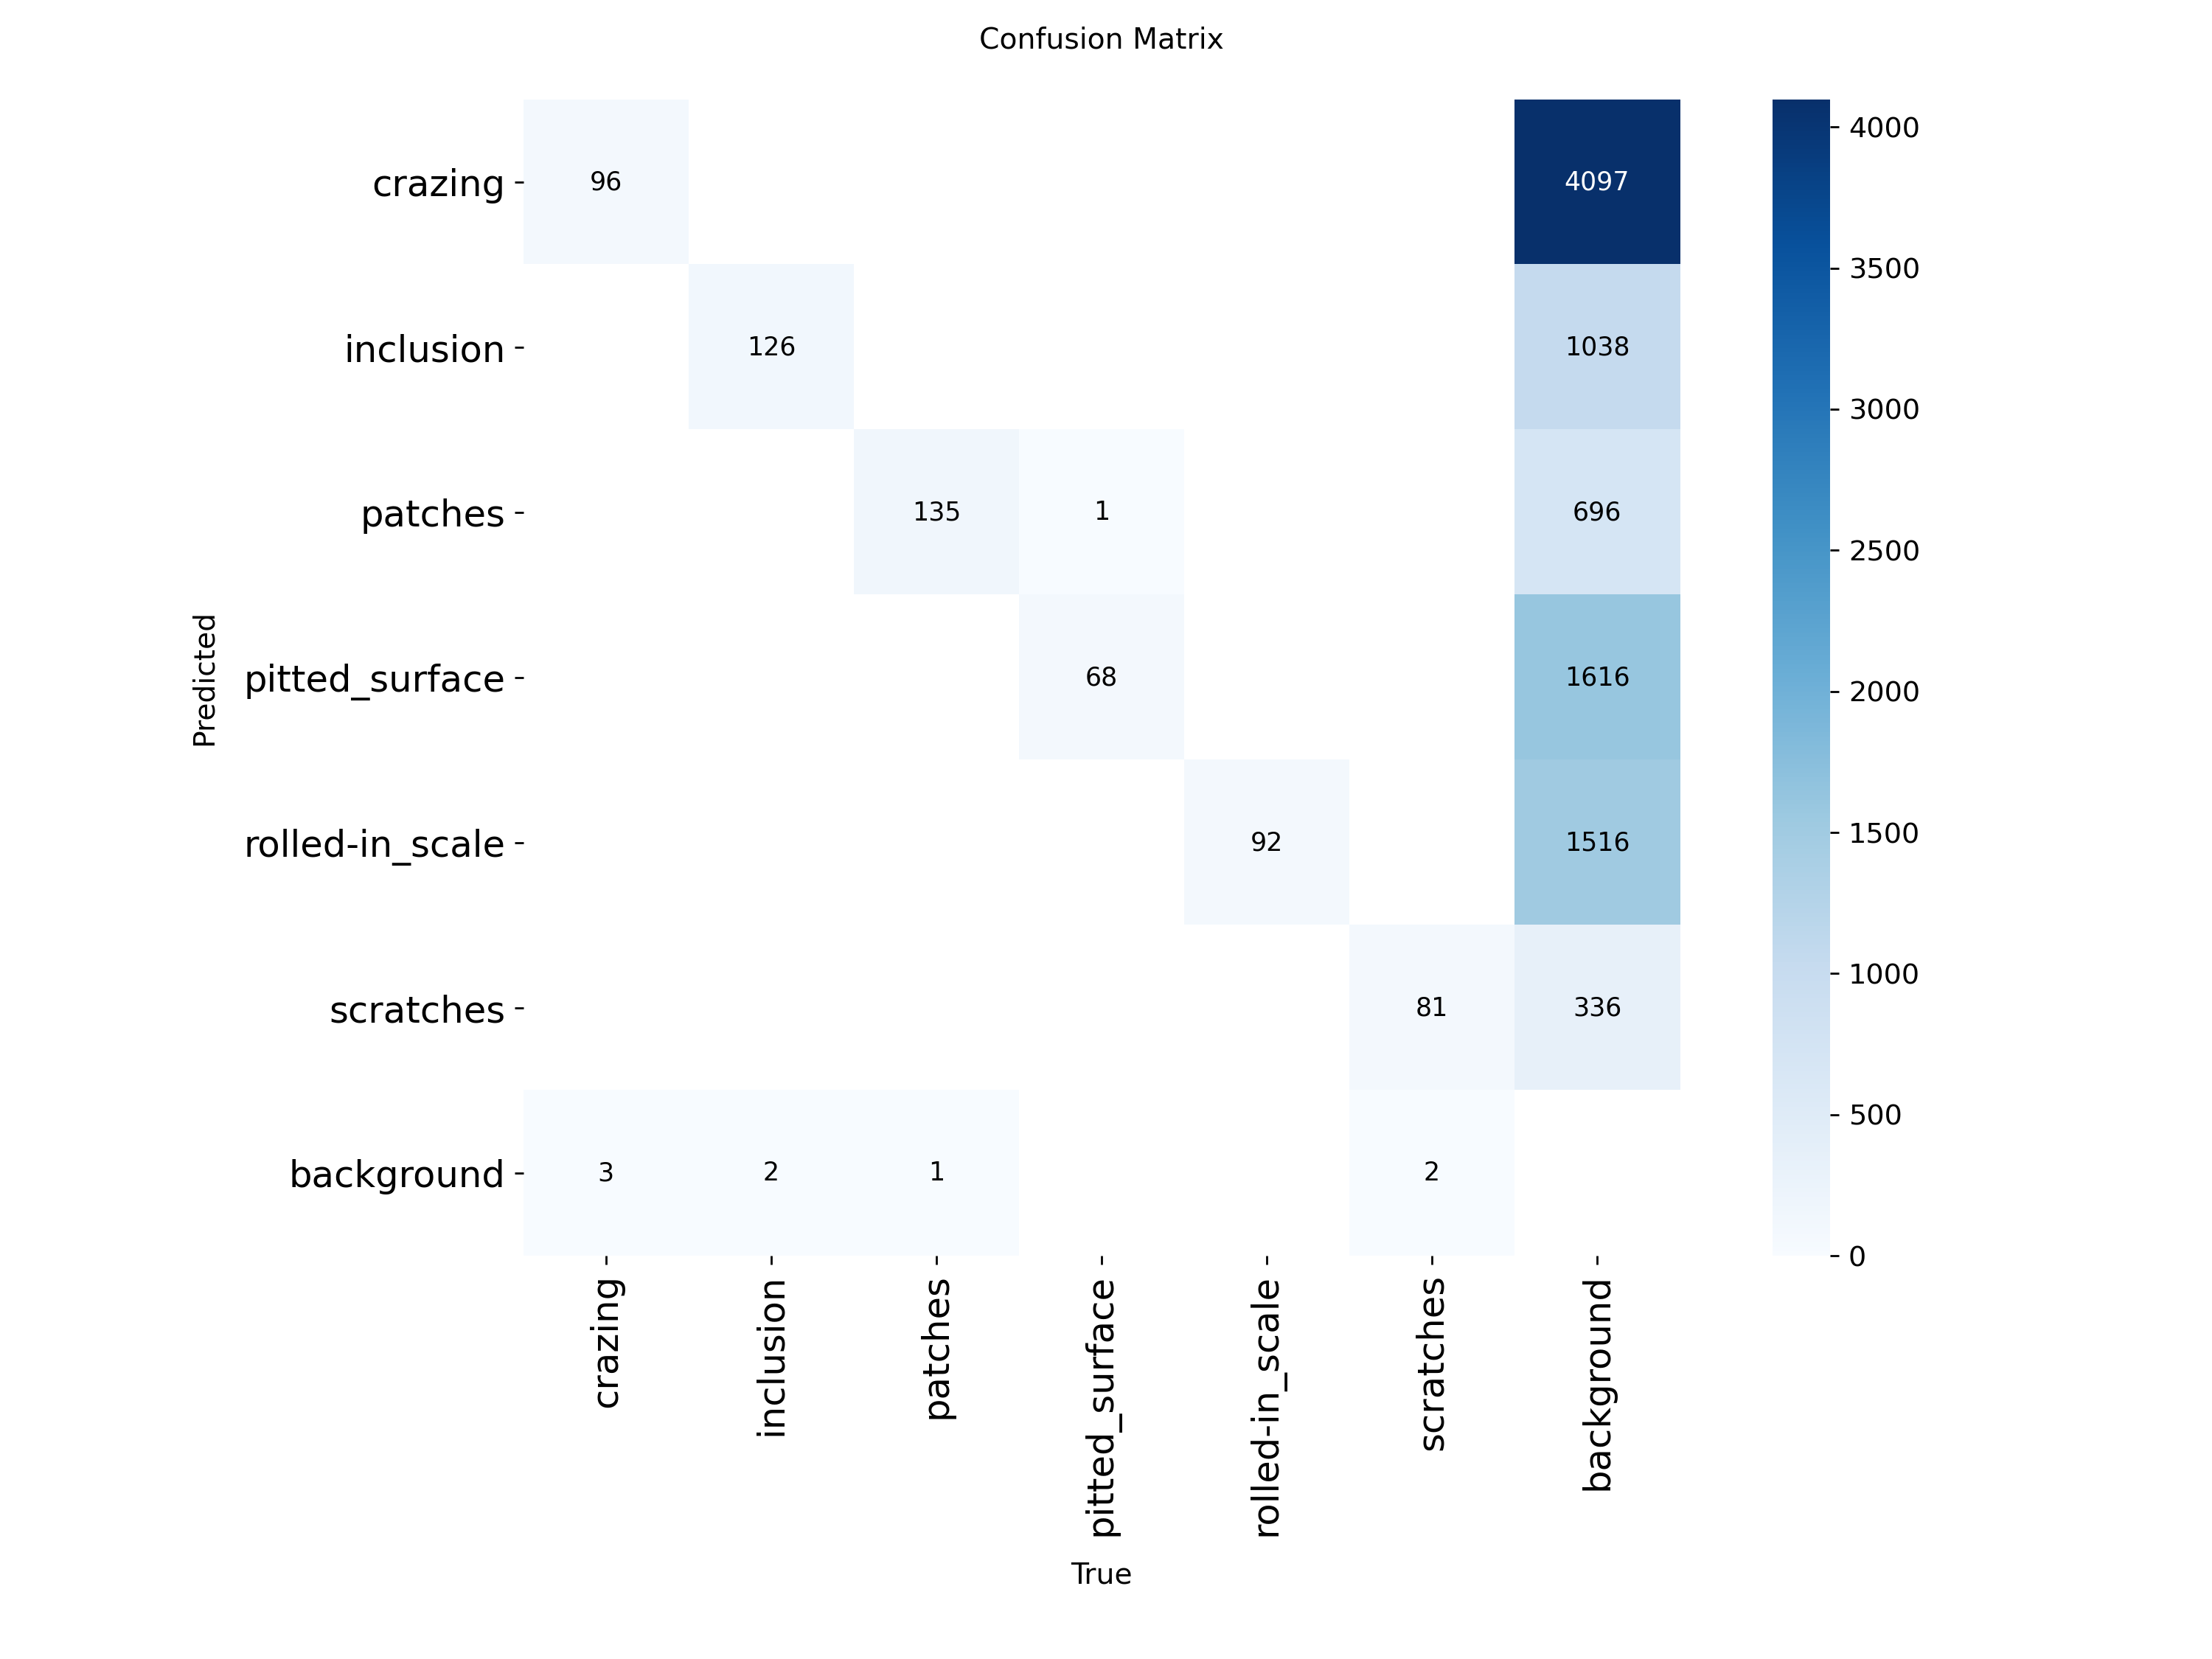

In [10]:
!python -m src.evaluate
from IPython.display import Image as IPImage, display
display(IPImage("reports/confusion_matrix.png"))

## Export model to ONNX and test predictions.

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 122 layers, 2,390,950 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from 'models/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 6) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: export success ✅ 1.1s, saved as 'models/best.onnx' (9.4 MB)

Export complete (1.5s)
Results saved to /content/defect-detection-mlops/models/best.onnx
Predict:         yolo predict task=detect model=models/best.onnx imgsz=640 
Validate:        yolo val task=detect model=models/best.onnx imgsz=640 data=/content/defect-detection-mlops/data/processed/data.yaml 
Visualize:       https://netron.app
parity OK on 3 sample image(s)
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00G

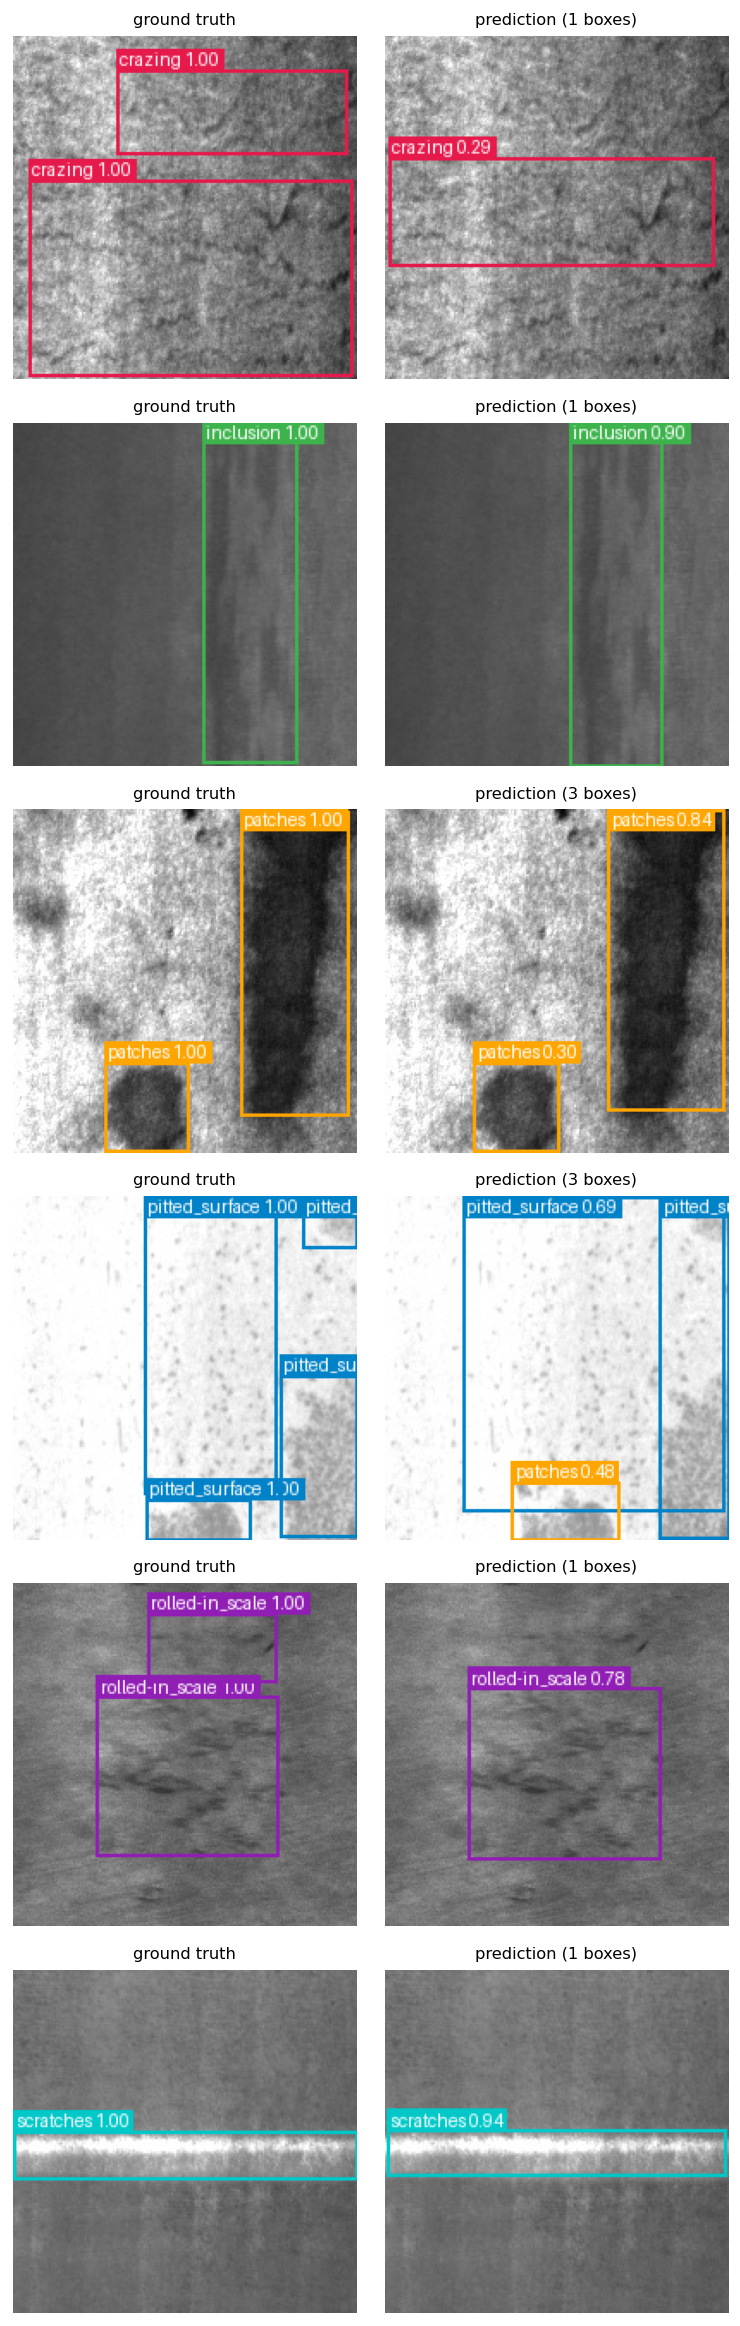

In [11]:
!python -m src.export_onnx
!python -m src.visualize
display(IPImage("reports/predictions_grid.png"))

## Drift reference and demo examples

In [12]:
!python -m src.make_reference
!python -m src.make_examples
!ls -lh models reports metrics examples

reference stats from 270 validation images -> reports/reference_stats.json
6 examples written to examples/
examples:
total 108K
-rw-r--r-- 1 root root  21K Oct 29 05:59 crazing.jpg
-rw-r--r-- 1 root root 8.4K Oct 29 05:59 inclusion.jpg
-rw-r--r-- 1 root root  21K Oct 29 05:59 patches.jpg
-rw-r--r-- 1 root root  13K Oct 29 05:59 pitted_surface.jpg
-rw-r--r-- 1 root root  15K Oct 29 05:59 rolled-in_scale.jpg
-rw-r--r-- 1 root root  13K Oct 29 05:59 scratches.jpg

metrics:
total 8.0K
-rw-r--r-- 1 root root 693 Oct 29 06:21 eval.json
-rw-r--r-- 1 root root 210 Oct 29 06:20 train.json

models:
total 15M
-rw-r--r-- 1 root root 5.3M Oct 29 06:20 best.pt
-rw-r--r-- 1 root root  284 Oct 29 06:21 classes.json
-rw-r--r-- 1 root root 9.4M Oct 29 06:21 model.onnx

reports:
total 1.7M
-rw-r--r-- 1 root root 288K Oct 29 06:21 BoxF1_curve.png
-rw-r--r-- 1 root root 193K Oct 29 06:21 BoxPR_curve.png
-rw-r--r-- 1 root root 192K Oct 29 06:21 confusion_matrix_normalized.png
-rw-r--r-- 1 root root 195K Oct

## Drift monitor

In [13]:
!python -m src.simulate_traffic --mode normal --n 200 --reset
!python -m src.monitor || true
!python -m src.simulate_traffic --mode drifted --n 200 --reset
!python -m src.monitor || true

logged 200 normal predictions -> logs/predictions.jsonl
{
  "n_current": 200,
  "n_reference": 270,
  "alpha": 0.01,
  "features": {
    "brightness": {
      "ks_stat": 0.0719,
      "p_value": 0.5626664636921848,
      "drift": false,
      "ref_mean": 0.4972,
      "cur_mean": 0.5066
    },
    "contrast": {
      "ks_stat": 0.1302,
      "p_value": 0.03644886223422334,
      "drift": false,
      "ref_mean": 0.1046,
      "cur_mean": 0.096
    },
    "n_detections": {
      "ks_stat": 0.057,
      "p_value": 0.8226587914794106,
      "drift": false,
      "ref_mean": 2.1222,
      "cur_mean": 2.125
    },
    "max_confidence": {
      "ks_stat": 0.0778,
      "p_value": 0.4618586777852336,
      "drift": false,
      "ref_mean": 0.6721,
      "cur_mean": 0.6996
    }
  },
  "drift_detected": false,
  "status": "ok"
}
logged 200 drifted predictions -> logs/predictions.jsonl
{
  "n_current": 200,
  "n_reference": 270,
  "alpha": 0.01,
  "features": {
    "brightness": {
      "ks_sta

## Artifacts

In [14]:
!zip -qr artifacts.zip models/model.onnx models/classes.json metrics reports examples
from google.colab import files as colab_files
colab_files.download("artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>